# Serotonin control and locomotion in modWorm

This notebook compares the unmodified model with a smooth 0–5 µM sinusoidal control using the repository's Varshney connectome, WormAtlas neuron-to-muscle map, touch stimulus, **Python proprioceptive full-body solver**, and the MOD-1 layer. The sine protocol starts and ends at zero and peaks halfway through the run. Optional constant-dose and full-body zero-dose controls are available in the simulation cell.

**Run cells from top to bottom.** The solver's Python path is intentional: the current serotonin hook is not wired into the Julia-compiled solver classes. `juliacall` remains imported through the project's `modWorm` package as configured in `modWorm/__init__.py`; Julia may take a while on first startup. The full simulation takes longer than the neural-only demo because it integrates muscles, body mechanics, and proprioceptive feedback.

This is a controlled model experiment, not a claim that MOD-1 alone reproduces all roaming/dwelling biology. Measure the output before interpreting behavioral direction. No neural, synaptic, muscle, or body parameters are changed between protocols.

In [1]:
from pathlib import Path
import json
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit

ROOT = Path.cwd().resolve()
if not (ROOT / "modWorm").is_dir():
    candidates = [ROOT.parent, *ROOT.parents]
    ROOT = next((p for p in candidates if (p / "modWorm").is_dir()), ROOT)
if not (ROOT / "modWorm").is_dir():
    raise FileNotFoundError("Open/run this notebook from the modWorm repository or its subdirectory.")
import os, sys
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

try:
    from modWorm import network_params as n_params, predefined_classes_nv, predefined_classes_mb
    from modWorm import proprioception_simulation as p_sim, utils
    from modWorm.serotonin import NEURON_INDICES, SerotoninModulation
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        f"A required modWorm/Python dependency is missing ({exc.name}). "
        "Select the project's Python environment and install the dependencies listed in README.md."
    ) from exc

print("Repository:", ROOT)
print("Serotonin API:", SerotoninModulation.__name__)


Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython
Repository: C:\Users\ecer\Desktop\CElegan\VSCode\MODWorm
Serotonin API: SerotoninModulation


## Load and verify the local model data

The repository already has the two `.xls` workbooks and the tutorial's gentle posterior touch input. The map constructor handles the old Excel format with `xlrd`; this cell checks that both connectomes and the muscle map have the expected 279-neuron shape.

In [2]:
CONNECTOME_FILE = ROOT / "database" / "NeuronConnect.xls"
NEURON_FIXED_POINTS_FILE = ROOT / "database" / "NeuronFixedPoints.xls"
PRESET_FILE = ROOT / "modWorm" / "presets_input" / "input_mat_gentle_post_touch.npy"
for path in (CONNECTOME_FILE, NEURON_FIXED_POINTS_FILE, PRESET_FILE):
    if not path.is_file():
        raise FileNotFoundError(f"Required local model input not found: {path}")

conn_gap, conn_syn = utils.construct_connectome_Varshney(str(CONNECTOME_FILE))
muscle_map = utils.construct_muscle_map_Hall(str(NEURON_FIXED_POINTS_FILE))
touch_input = np.load(PRESET_FILE)
assert conn_gap.shape == conn_syn.shape == (279, 279)
assert muscle_map.shape[1] == 279
assert touch_input.ndim == 2 and touch_input.shape[1] == 279
print(f"Gap connectome: {conn_gap.shape}; {np.count_nonzero(conn_gap)} nonzero entries")
print(f"Chemical connectome: {conn_syn.shape}; {np.count_nonzero(conn_syn)} nonzero entries")
print(f"Neuron-to-muscle map: {muscle_map.shape}; {np.count_nonzero(muscle_map)} nonzero entries")
print(f"Touch input: {touch_input.shape}; duration {((len(touch_input) - 1) * 0.01):.2f} s")


Gap connectome: (279, 279); 1122 nonzero entries
Chemical connectome: (279, 279); 2305 nonzero entries
Neuron-to-muscle map: (96, 279); 507 nonzero entries
Touch input: (1400, 279); duration 13.99 s


In [3]:
with (ROOT / "modWorm" / "neurons.json").open(encoding="utf-8") as f:
    neuron_records = json.load(f)["neurons"]
indices_by_name = {item["name"]: item["index"] for item in neuron_records}
for neuron_name, expected_index in NEURON_INDICES.items():
    assert indices_by_name.get(neuron_name) == expected_index, (neuron_name, expected_index)
assert "NSM" not in indices_by_name, "Re-check the connectome mapping before using an NSM index."
AIY_INDICES = np.array([indices_by_name["AIYL"], indices_by_name["AIYR"]])
print("AIYL/AIYR zero-based indices:", AIY_INDICES.tolist())
print("Verified optional targets:", {name: indices_by_name[name] for name in ("ASIL", "ASIR", "RIFL", "RIFR")})
print("NSM is absent from this 279-neuron list; it is not added or simulated as a source.")


AIYL/AIYR zero-based indices: [137, 133]
Verified optional targets: {'ASIL': 75, 'ASIR': 89, 'RIFL': 158, 'RIFR': 148}
NSM is absent from this 279-neuron list; it is not added or simulated as a source.


## Set the stimulation and serotonin waveform

The preset is sampled at 10 ms. By default the run spans that full 13.99 s input, and one cosine-shaped cycle (`f = 1 / duration`, about 0.071 Hz) gives a smooth 0 → 5 → 0 µM modulation with zero slope at both endpoints. The chosen frequency is for observing a complete control cycle in this available stimulus window, not a measured biological frequency. Edit `SINE_PERIOD_S` to explore slower/faster control; the waveform is clipped to its stated nonnegative range. Concentration is passed as a time callable, not appended as an ODE state.

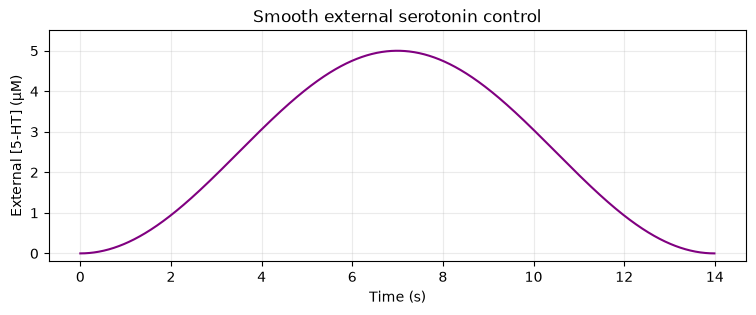

Run duration: 13.99 s; period: 13.99 s; frequency: 0.0715 Hz


In [4]:
DT = 0.01  # seconds; matches the model's network timescale
SIM_DURATION_S = (len(touch_input) - 1) * DT
SINE_PERIOD_S = SIM_DURATION_S  # one full, smooth cycle in this run
SEROTONIN_MAX_UM = 5.0
CONSTANT_DOSE_UM = 5.0

time_s = np.arange(len(touch_input)) * DT
if abs(time_s[-1] - SIM_DURATION_S) > 1e-10:
    raise ValueError("Input duration and configured timestep are inconsistent.")
if SINE_PERIOD_S <= 0:
    raise ValueError("SINE_PERIOD_S must be positive.")

def serotonin_sine(t):
    """Smooth 0-to-peak-to-0 MOD-1 control concentration in micromolar."""
    phase_time = np.clip(t, 0.0, time_s[-1])
    concentration = 0.5 * SEROTONIN_MAX_UM * (1.0 - np.cos(2.0 * np.pi * phase_time / SINE_PERIOD_S))
    return float(np.clip(concentration, 0.0, SEROTONIN_MAX_UM))

serotonin_sine_um = np.array([serotonin_sine(t) for t in time_s])
assert np.isclose(serotonin_sine_um.min(), 0.0, atol=1e-10)
assert np.isclose(serotonin_sine_um.max(), SEROTONIN_MAX_UM, atol=1e-10)
assert np.all(serotonin_sine_um >= 0.0)

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(time_s, serotonin_sine_um, color="purple")
ax.set(xlabel="Time (s)", ylabel="External [5-HT] (µM)", ylim=(-0.2, SEROTONIN_MAX_UM + 0.5), title="Smooth external serotonin control")
ax.grid(alpha=0.25)
plt.show()
print(f"Run duration: {SIM_DURATION_S:.2f} s; period: {SINE_PERIOD_S:.2f} s; frequency: {1 / SINE_PERIOD_S:.4f} Hz")


## Build matched full-model scenarios and simulate

All scenarios share the same initial network/body state and the same sensory input. The default is a baseline-versus-sinusoid comparison; enable `RUN_ZERO_DOSE_CONTROL` and/or `RUN_CONSTANT_DOSE_CONTROL` in the next cell for extra full-body runs. The exact zero-dose no-op is also covered by the focused unit tests. The `PPC` classes and `p_sim.run_network` preserve the tutorial's proprioceptive full-body workflow; they are the Python implementations.

In [5]:
# Seed only the initial-condition draw; every scenario receives an exact copy.
np.random.seed(2026)
reference_nv = predefined_classes_nv.CelegansWorm_NervousSystem_PPC(conn_gap, conn_syn)
reference_mb = predefined_classes_mb.CelegansWorm_MuscleBody_PPC(muscle_map)
initial_network_state = reference_nv.initcond.copy()
initial_body_state = reference_mb.initcond.copy()
gap_reference = reference_nv.network_Electrical.copy()
syn_reference = reference_nv.network_Chemical.copy()

def make_scenario(concentration_control=None):
    """Create a fresh, matched nervous system/body pair."""
    nv = predefined_classes_nv.CelegansWorm_NervousSystem_PPC(conn_gap, conn_syn)
    mb = predefined_classes_mb.CelegansWorm_MuscleBody_PPC(muscle_map)
    nv.initcond = initial_network_state.copy()
    mb.initcond = initial_body_state.copy()
    if concentration_control is not None:
        nv.serotonin_modulation = SerotoninModulation(
            g_mod1=2.0, k_d=1.0, hill_coefficient=1.0, e_cl=-70.0,
            concentration=concentration_control,
            target_neurons=("AIYL", "AIYR"),
        )
    return nv, mb

# Two matched full-body runs are the efficient default. Enable either optional
# control below when you want the extra, expensive body simulation.
RUN_ZERO_DOSE_CONTROL = False
RUN_CONSTANT_DOSE_CONTROL = False

scenario_controls = {
    "Base (layer absent)": None,
    "Sinusoidal 0–5 µM": serotonin_sine,
}
if RUN_ZERO_DOSE_CONTROL:
    scenario_controls["Zero 5-HT (layer on)"] = 0.0
if RUN_CONSTANT_DOSE_CONTROL:
    scenario_controls["Constant 5 µM"] = CONSTANT_DOSE_UM

models = {name: make_scenario(control) for name, control in scenario_controls.items()}
results = {}
for name, (nv, mb) in models.items():
    started = time.perf_counter()
    results[name] = p_sim.run_network(nv, mb, touch_input)
    print(f"{name}: {time.perf_counter() - started:.1f} s")

print(f"Finished {len(results)} matched full-body simulations.")


C:\Users\ecer\Desktop\CElegan\VSCode\MODWorm\modWorm\network_dynamics.py:80: RuntimeWarning: overflow encountered in exp
  synaptic_rise = np.multiply(np.multiply(self.neuron_Chemical[0], (1 - s)), np.reciprocal(1 + np.exp(-self.neuron_Chemical[2]*(v - vth))))
C:\Users\ecer\Desktop\CElegan\VSCode\MODWorm\modWorm\network_interactions.py:102: RuntimeWarning: overflow encountered in exp
  sigmoid_V = np.reciprocal(1.0 + np.exp(-self.neuron_Chemical[2]*(v - vth))) # n


Base (layer absent): 5878.2 s
Sinusoidal 0–5 µM: 990.2 s
Finished 2 matched full-body simulations.


In [6]:
base = results["Base (layer absent)"]
if "Zero 5-HT (layer on)" in results:
    zero = results["Zero 5-HT (layer on)"]
    for key in ("v_solution", "s_solution", "v_threshold", "muscle_force", "phi", "x_solution", "y_solution"):
        np.testing.assert_array_equal(zero[key], base[key], err_msg=f"zero-dose mismatch in {key}")
    print("PASS: zero 5-HT full-body outputs are bitwise identical to base.")

# Compare actual connectome matrices after all selected simulations.
for name, (nv, _) in models.items():
    np.testing.assert_array_equal(nv.network_Electrical, gap_reference, err_msg=f"gap matrix changed in {name}")
    np.testing.assert_array_equal(nv.network_Chemical, syn_reference, err_msg=f"chemical matrix changed in {name}")

def sigmoid_drive(solution):
    """Synaptic sigmoid drive for AIYL/AIYR (not a spike-rate measurement)."""
    voltage_delta = solution["v_solution"][:, AIY_INDICES] - solution["v_threshold"][:, AIY_INDICES]
    widths = n_params.CE.B[AIY_INDICES]
    return expit(voltage_delta * widths)

def center_of_mass_speed(solution):
    """Body-center displacement speed from the simulated centerline (model units/s)."""
    x_center = np.mean(solution["x_solution"], axis=1)
    y_center = np.mean(solution["y_solution"], axis=1)
    speed = np.hypot(np.diff(x_center), np.diff(y_center)) / DT
    return 0.5 * (time_s[1:] + time_s[:-1]), speed

def edge_corrected_mean(values, width):
    width = max(1, int(width))
    kernel = np.ones(width, dtype=float)
    return np.convolve(values, kernel, mode="same") / np.convolve(np.ones_like(values), kernel, mode="same")

aiy_drive = {name: sigmoid_drive(solution).mean(axis=1) for name, solution in results.items()}
speed_traces = {name: center_of_mass_speed(solution) for name, solution in results.items()}
for name, drive in aiy_drive.items():
    print(f"{name:24s} mean AIY sigmoid drive: {drive.mean():.5f}")
for name, (_, speed) in speed_traces.items():
    print(f"{name:24s} mean center speed:      {speed.mean():.5f} model units/s")
if "Zero 5-HT (layer on)" not in results:
    print("Zero-dose no-op is covered by the focused RHS regression test; set RUN_ZERO_DOSE_CONTROL=True for a full-body comparison.")
print("PASS: all gap-junction and chemical connectome arrays remain unchanged.")


Base (layer absent)      mean AIY sigmoid drive: 0.50710
Sinusoidal 0–5 µM        mean AIY sigmoid drive: 0.03816
Base (layer absent)      mean center speed:      5.04025 model units/s
Sinusoidal 0–5 µM        mean center speed:      4.92040 model units/s
Zero-dose no-op is covered by the focused RHS regression test; set RUN_ZERO_DOSE_CONTROL=True for a full-body comparison.
PASS: all gap-junction and chemical connectome arrays remain unchanged.


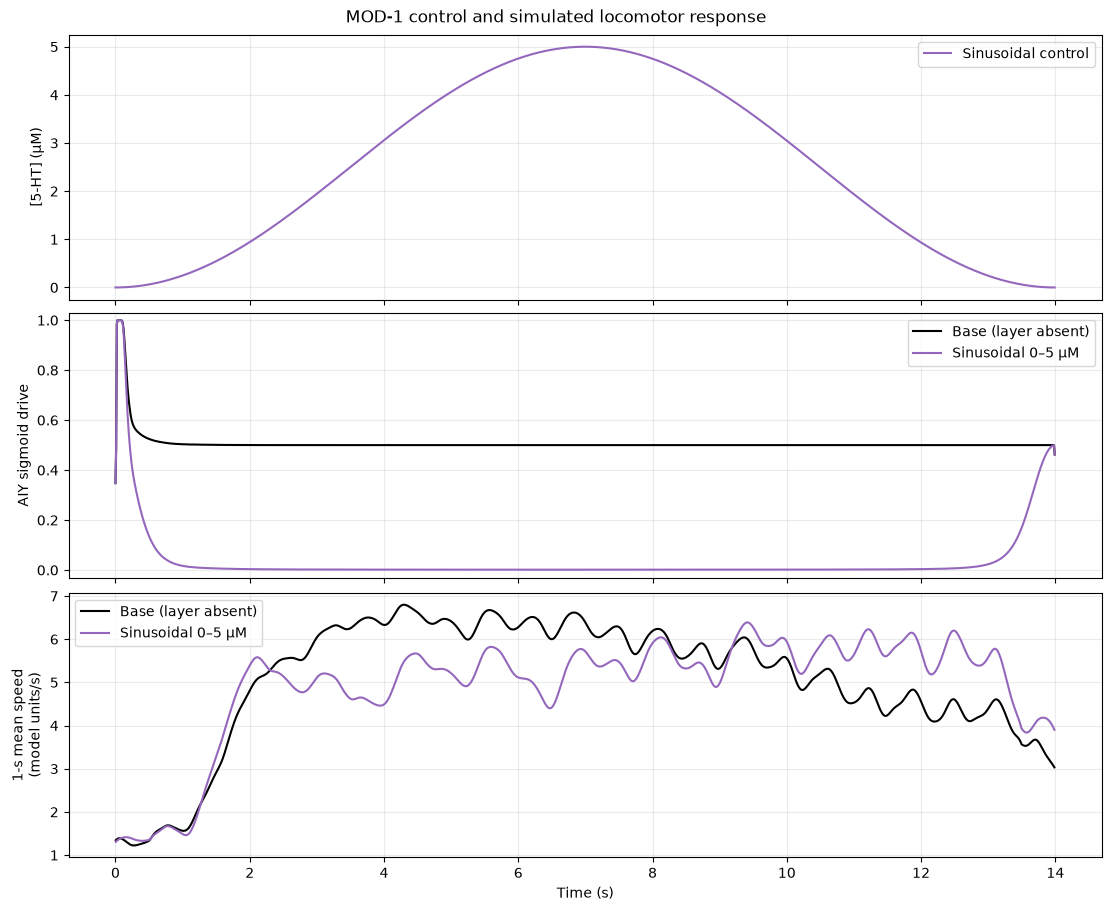

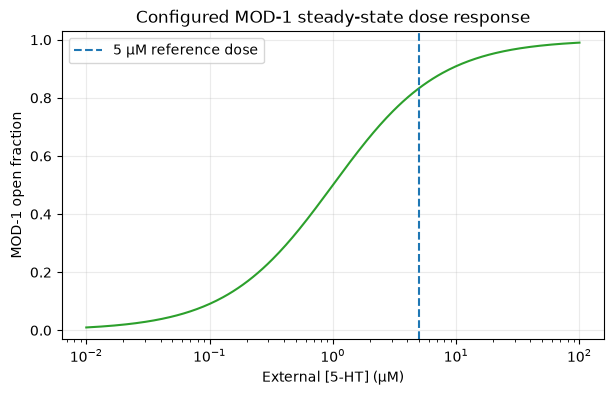

In [7]:
plot_names = [name for name in ("Base (layer absent)", "Constant 5 µM", "Sinusoidal 0–5 µM") if name in results]
colors = {"Base (layer absent)": "black", "Constant 5 µM": "tab:blue", "Sinusoidal 0–5 µM": "tab:purple"}
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True, constrained_layout=True)

axes[0].plot(time_s, serotonin_sine_um, color=colors["Sinusoidal 0–5 µM"], label="Sinusoidal control")
if "Constant 5 µM" in results:
    axes[0].axhline(CONSTANT_DOSE_UM, color=colors["Constant 5 µM"], linestyle="--", label="Constant 5 µM")
axes[0].set_ylabel("[5-HT] (µM)")
axes[0].legend(loc="upper right")

for name in plot_names:
    axes[1].plot(time_s, aiy_drive[name], color=colors[name], label=name)
axes[1].set_ylabel("AIY sigmoid drive")
axes[1].set_ylim(-0.03, 1.03)
axes[1].legend(loc="best")

for name in plot_names:
    speed_time, speed = speed_traces[name]
    axes[2].plot(speed_time, edge_corrected_mean(speed, round(1.0 / DT)), color=colors[name], label=name)
axes[2].set_ylabel("1-s mean speed\n(model units/s)")
axes[2].set_xlabel("Time (s)")
axes[2].legend(loc="best")
for ax in axes:
    ax.grid(alpha=0.25)
fig.suptitle("MOD-1 control and simulated locomotor response")
plt.show()

# Dose-response panel is the configured steady-state MOD-1 Hill curve, not a claim of measured behavior.
dose_um = np.logspace(-2, 2, 300)
g_mod1, kd_um, hill_n = 2.0, 1.0, 1.0
receptor_open_fraction = dose_um**hill_n / (kd_um**hill_n + dose_um**hill_n)
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogx(dose_um, receptor_open_fraction, color="tab:green")
ax.axvline(CONSTANT_DOSE_UM, color="tab:blue", linestyle="--", label="5 µM reference dose")
ax.set(xlabel="External [5-HT] (µM)", ylabel="MOD-1 open fraction", ylim=(-0.03, 1.03), title="Configured MOD-1 steady-state dose response")
ax.grid(alpha=0.25)
ax.legend()
plt.show()


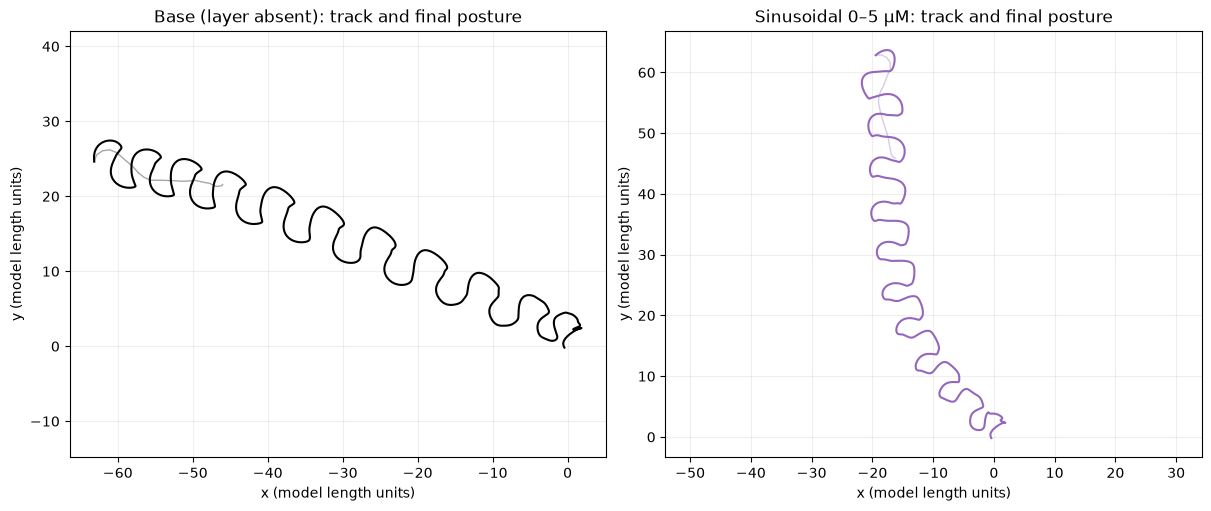

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, name in zip(axes, ("Base (layer absent)", "Sinusoidal 0–5 µM")):
    solution = results[name]
    x_body, y_body = solution["x_solution"], solution["y_solution"]
    ax.plot(x_body[:, 0], y_body[:, 0], color=colors[name], linewidth=1.5)
    ax.plot(x_body[-1], y_body[-1], color=colors[name], alpha=0.35, linewidth=1)
    ax.set_title(f"{name}: track and final posture")
    ax.set_xlabel("x (model length units)")
    ax.set_ylabel("y (model length units)")
    ax.axis("equal")
    ax.grid(alpha=0.2)
plt.show()


## Create a side-by-side locomotion animation

The default output is a compact GIF made with Matplotlib's Pillow writer, which does not require an external FFmpeg executable. If FFmpeg is available to Matplotlib, the same comparison is also exported as MP4. The GIF is frame-thinned for reasonable file size; it does not alter the underlying simulation.

Saved animation: C:\Users\ecer\Desktop\CElegan\VSCode\MODWorm\created_vids\serotonin\serotonin_sine_locomotion.gif
FFmpeg is not available to Matplotlib; GIF export succeeded and is the portable animation output.


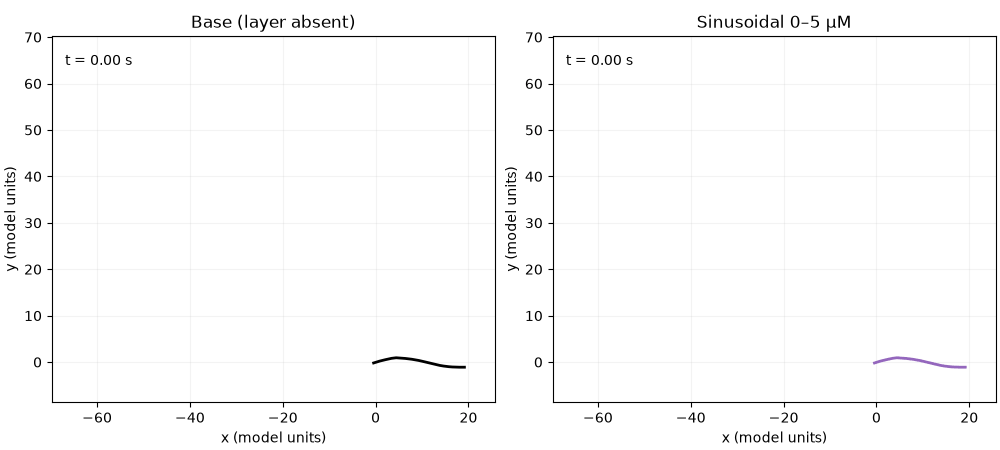

In [9]:
from matplotlib import animation as mpl_animation
from IPython.display import Image, display

frame_stride = max(1, len(time_s) // 250)
frame_indices = np.arange(0, len(time_s), frame_stride)
if frame_indices[-1] != len(time_s) - 1:
    frame_indices = np.append(frame_indices, len(time_s) - 1)
animation_names = ["Base (layer absent)", "Sinusoidal 0–5 µM"]
all_x = np.concatenate([results[name]["x_solution"][frame_indices].ravel() for name in animation_names])
all_y = np.concatenate([results[name]["y_solution"][frame_indices].ravel() for name in animation_names])
margin = 0.08 * max(np.ptp(all_x), np.ptp(all_y), 1.0)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
body_lines = []
time_labels = []
for ax, name in zip(axes, animation_names):
    line, = ax.plot([], [], color=colors[name], linewidth=2)
    label = ax.text(0.03, 0.95, "", transform=ax.transAxes, va="top")
    ax.set_xlim(all_x.min() - margin, all_x.max() + margin)
    ax.set_ylim(all_y.min() - margin, all_y.max() + margin)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(name)
    ax.set_xlabel("x (model units)")
    ax.set_ylabel("y (model units)")
    ax.grid(alpha=0.15)
    body_lines.append(line)
    time_labels.append(label)

def update_animation(frame_number):
    sample = frame_indices[frame_number]
    for line, label, name in zip(body_lines, time_labels, animation_names):
        line.set_data(results[name]["x_solution"][sample], results[name]["y_solution"][sample])
        label.set_text(f"t = {time_s[sample]:.2f} s")
    return body_lines + time_labels

worm_animation = mpl_animation.FuncAnimation(
    fig, update_animation, frames=len(frame_indices), interval=50,
    blit=True, repeat=True,
)
output_dir = ROOT / "created_vids" / "serotonin"
output_dir.mkdir(parents=True, exist_ok=True)
gif_path = output_dir / "serotonin_sine_locomotion.gif"
try:
    worm_animation.save(gif_path, writer=mpl_animation.PillowWriter(fps=15))
except (ImportError, RuntimeError) as exc:
    raise RuntimeError(
        "GIF export needs Pillow in the active notebook environment. "
        "Install Pillow in that environment, then rerun this cell."
    ) from exc
print("Saved animation:", gif_path)

if mpl_animation.writers.is_available("ffmpeg"):
    mp4_path = output_dir / "serotonin_sine_locomotion.mp4"
    worm_animation.save(mp4_path, writer=mpl_animation.FFMpegWriter(fps=15, bitrate=1600))
    print("Saved MP4:", mp4_path)
else:
    print("FFmpeg is not available to Matplotlib; GIF export succeeded and is the portable animation output.")
plt.close(fig)
display(Image(filename=str(gif_path)))


In [10]:
output_npz = ROOT / "created_vids" / "serotonin" / "serotonin_locomotion_metrics.npz"
np.savez_compressed(
    output_npz,
    time_s=time_s,
    serotonin_sine_um=serotonin_sine_um,
    aiy_drive_base=aiy_drive["Base (layer absent)"],
    aiy_drive_constant_5um=aiy_drive["Constant 5 µM"],
    aiy_drive_sine=aiy_drive["Sinusoidal 0–5 µM"],
    speed_time_s=speed_traces["Sinusoidal 0–5 µM"][0],
    speed_sine=speed_traces["Sinusoidal 0–5 µM"][1],
)
print("Saved reproducible time-series metrics:", output_npz)
print("No packages were installed by this notebook. The active environment must provide the dependencies in README.md, including Pillow for GIF output.")


KeyError: 'Constant 5 µM'